# 02. Métodos de reducción de dimensionalidad
**Ringo - Inteligencia de Negocio**

Queremos representar en 2D a los hogares, que están descritos por 7 variables, sin perder qué hogares se parecen entre sí.
Comparamos un método lineal (PCA) con tres no lineales (Isomap, t-SNE y UMAP).
Primero los probamos con el swiss roll, donde sabemos cuál es la respuesta correcta, y después los aplicamos a los hogares.
El mejor mapa se guarda en `salidas/mapas.csv` para la parte de Segmentos.

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap, TSNE, trustworthiness
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
import umap

SEED = 42

## 1. Prueba con el swiss roll
El swiss roll es una hoja enrollada en 3D. Sabemos cómo debería quedar desenrollada,
así que sirve para comprobar qué métodos funcionan antes de usar los datos reales.
El color (`t`) indica la posición de cada punto a lo largo del rollo: si un método lo desenrolla bien, el color sale en degradado.

(1500, 3)


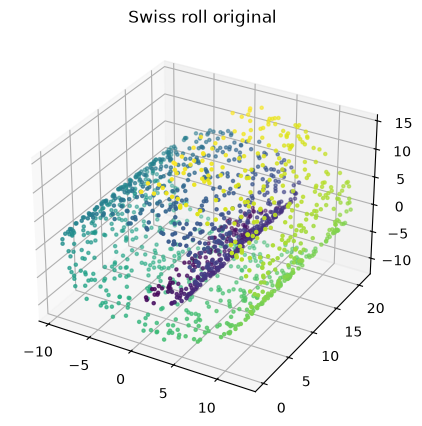

In [54]:
X, t = make_swiss_roll(n_samples=1500, noise=0.05, random_state=SEED)
print(X.shape)

fig = plt.figure(figsize=(6,5))
ax= fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, cmap="viridis", s=5)
ax.set_title("Swiss roll original")
plt.savefig("../salidas/figuras/02_swiss_roll_3d.png", dpi=150)
plt.show()

## 2. Aplicar los cuatro métodos
Cada método reduce los puntos de 3D a 2D (`n_components=2`):
- **PCA:** busca las 2 direcciones con más varianza y proyecta los puntos, como una sombra. Es lineal.
- **Isomap:** une cada punto con sus vecinos y mide las distancias por la superficie (geodésicas).
- **t-SNE:** intenta que los vecinos cercanos en 3D sigan juntos en 2D.
- **UMAP:** construye una red de vecinos como Isomap y coloca los puntos como t-SNE; conserva mejor la forma global.

t-SNE y UMAP tienen una parte aleatoria, por eso fijamos la semilla (`SEED = 42`) para que los resultados sean siempre iguales.

In [57]:
# PCA: busca las 2 direcciones donde los datos esten mas dispersos
pca = PCA(n_components=2)
Y_pca = pca.fit_transform(X)

# Isomap: 10 vecinos mas cercanos como por carretera
isomap = Isomap(n_neighbors=10, n_components=2)
Y_isomap = isomap.fit_transform(X)

# t-SNE: intenta que los vecinos cercanos en el 3D sigan siendolo en el 2D y lo de perplexity son los vecinos consideran los nodos
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED)
Y_tsne = tsne.fit_transform(X)

# UMAP: es uan mezcla de la red de vecinos de isomap y colocalr los puntos en el 2D como t-SNE
modelo_umap = umap.UMAP(n_neighbors=15, n_components=2, random_state=SEED, compatibility_layout=True, n_jobs=1)
Y_umap = modelo_umap.fit_transform(X)

print(Y_pca.shape, Y_isomap.shape, Y_tsne.shape, Y_umap.shape)

(1500, 2) (1500, 2) (1500, 2) (1500, 2)


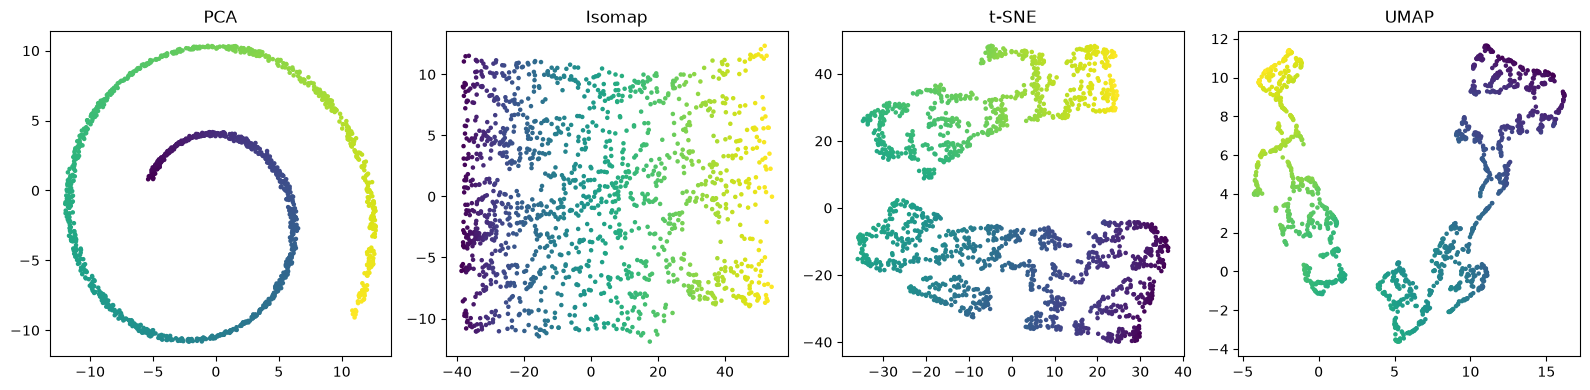

In [58]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].scatter(Y_pca[:, 0], Y_pca[:, 1], c=t, cmap="viridis", s=5)
axes[0].set_title("PCA")

axes[1].scatter(Y_isomap[:, 0], Y_isomap[:, 1], c=t, cmap="viridis", s=5)
axes[1].set_title("Isomap")

axes[2].scatter(Y_tsne[:, 0], Y_tsne[:, 1], c=t, cmap="viridis", s=5)
axes[2].set_title("t-SNE")

axes[3].scatter(Y_umap[:, 0], Y_umap[:, 1], c=t, cmap="viridis", s=5)
axes[3].set_title("UMAP")

plt.tight_layout()
plt.savefig("../salidas/figuras/02_mapas_swiss_roll.png", dpi=150)
plt.show()

## 3. Medir la calidad de los mapas
Usamos dos métricas que se complementan:
- **Confianza (`trustworthiness`):** comprueba si los 10 vecinos de cada punto en el mapa también eran vecinos en los datos originales. De 0 a 1.
- **Correlación de distancias (Spearman):** comprueba si los pares de puntos que estaban más lejos siguen siendo los más lejanos en el mapa. De -1 a 1.

In [59]:
def correlacion_distancias(X, Y):
    d_original = pdist(X)
    d_mapa = pdist(Y)
    return spearmanr(d_original, d_mapa).correlation

print("Funciones listas")

Funciones listas


In [60]:
print("PCA      | confianza:", round(trustworthiness(X, Y_pca, n_neighbors=10), 3),
      "| distancias:", round(correlacion_distancias(X, Y_pca), 3))
print("Isomap   | confianza:", round(trustworthiness(X, Y_isomap, n_neighbors=10), 3),
      "| distancias:", round(correlacion_distancias(X, Y_isomap), 3))
print("t-SNE    | confianza:", round(trustworthiness(X, Y_tsne, n_neighbors=10), 3),
      "| distancias:", round(correlacion_distancias(X, Y_tsne), 3))
print("UMAP     | confianza:", round(trustworthiness(X, Y_umap, n_neighbors=10), 3),
      "| distancias:", round(correlacion_distancias(X, Y_umap), 3))

PCA      | confianza: 0.897 | distancias: 0.848
Isomap   | confianza: 1.0 | distancias: 0.362
t-SNE    | confianza: 1.0 | distancias: 0.349
UMAP     | confianza: 0.999 | distancias: 0.277


In [61]:
resultados = pd.DataFrame({
    "metodo": ["PCA", "Isomap", "t-SNE", "UMAP"],
    "confianza": [trustworthiness(X, Y_pca, n_neighbors=10),
                  trustworthiness(X, Y_isomap, n_neighbors=10),
                  trustworthiness(X, Y_tsne, n_neighbors=10),
                  trustworthiness(X, Y_umap, n_neighbors=10)],
    "distancias": [correlacion_distancias(X, Y_pca),
                   correlacion_distancias(X, Y_isomap),
                   correlacion_distancias(X, Y_tsne),
                   correlacion_distancias(X, Y_umap)],
}).round(3)

resultados

,metodo,confianza,distancias
0,PCA,0.897,0.848
1,Isomap,1.000,0.362
2,t-SNE,1.000,0.349
3,UMAP,0.999,0.277


**Conclusión swiss roll:** (pendiente)

## 4. Cargar los hogares
Leemos la tabla que prepara Datos: una fila por hogar y 7 variables ya transformadas y escaladas.
Separamos `household_key`, porque es un identificador y no un hábito de compra: si lo dejáramos,
los métodos considerarían parecidos a hogares solo porque sus números de identificación están cerca.

In [62]:
hogares = pd.read_csv("../salidas/hogares.csv")
print(hogares.shape)

claves = hogares["household_key"]
X_hog = hogares.drop(columns=["household_key"])
print(X_hog.shape)
X_hog.head()

(2475, 8)
(2475, 7)


,n_visitas,gasto_medio_cesta,recencia,variedad,pct_marca_propia,pct_fresco,pct_descuento
0,0.234399,1.030185,-0.191497,0.262630,-1.407241,-0.537806,-0.420236
1,-0.455936,0.782035,1.187818,0.551246,-0.657954,-0.341226,-0.290188
2,-0.432639,1.246084,0.089197,-0.159194,-0.936366,0.044979,0.765806
3,-0.883455,0.644480,1.643657,-1.180452,-1.451525,-1.057652,-1.225413
4,-0.580588,-0.545775,0.089197,-0.891836,-0.431186,0.049703,-0.533461


## 5. Mapas de los hogares
Aplicamos los cuatro métodos a los hogares. Para ver cómo influyen los parámetros, probamos dos valores en cada método no lineal:
Isomap con 10 y 30 vecinos, t-SNE con perplejidad 30 y 50, y UMAP con 15 y 50 vecinos.

In [63]:
# PCA (no tiene parámetro que variar)
Y_pca_h = PCA(n_components=2).fit_transform(X_hog)

# Isomap con 10 y 30 vecinos
Y_iso10 = Isomap(n_neighbors=10, n_components=2).fit_transform(X_hog)
Y_iso30 = Isomap(n_neighbors=30, n_components=2).fit_transform(X_hog)

# t-SNE con perplejidad 30 y 50
Y_tsne30 = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(X_hog)
Y_tsne50 = TSNE(n_components=2, perplexity=50, random_state=SEED).fit_transform(X_hog)

# UMAP con 15 y 50 vecinos
Y_umap15 = umap.UMAP(n_neighbors=15, n_components=2, random_state=SEED, compatibility_layout=True, n_jobs=1).fit_transform(X_hog)
Y_umap50 = umap.UMAP(n_neighbors=50, n_components=2, random_state=SEED, compatibility_layout=True, n_jobs=1).fit_transform(X_hog)

print("Mapas calculados")

Mapas calculados


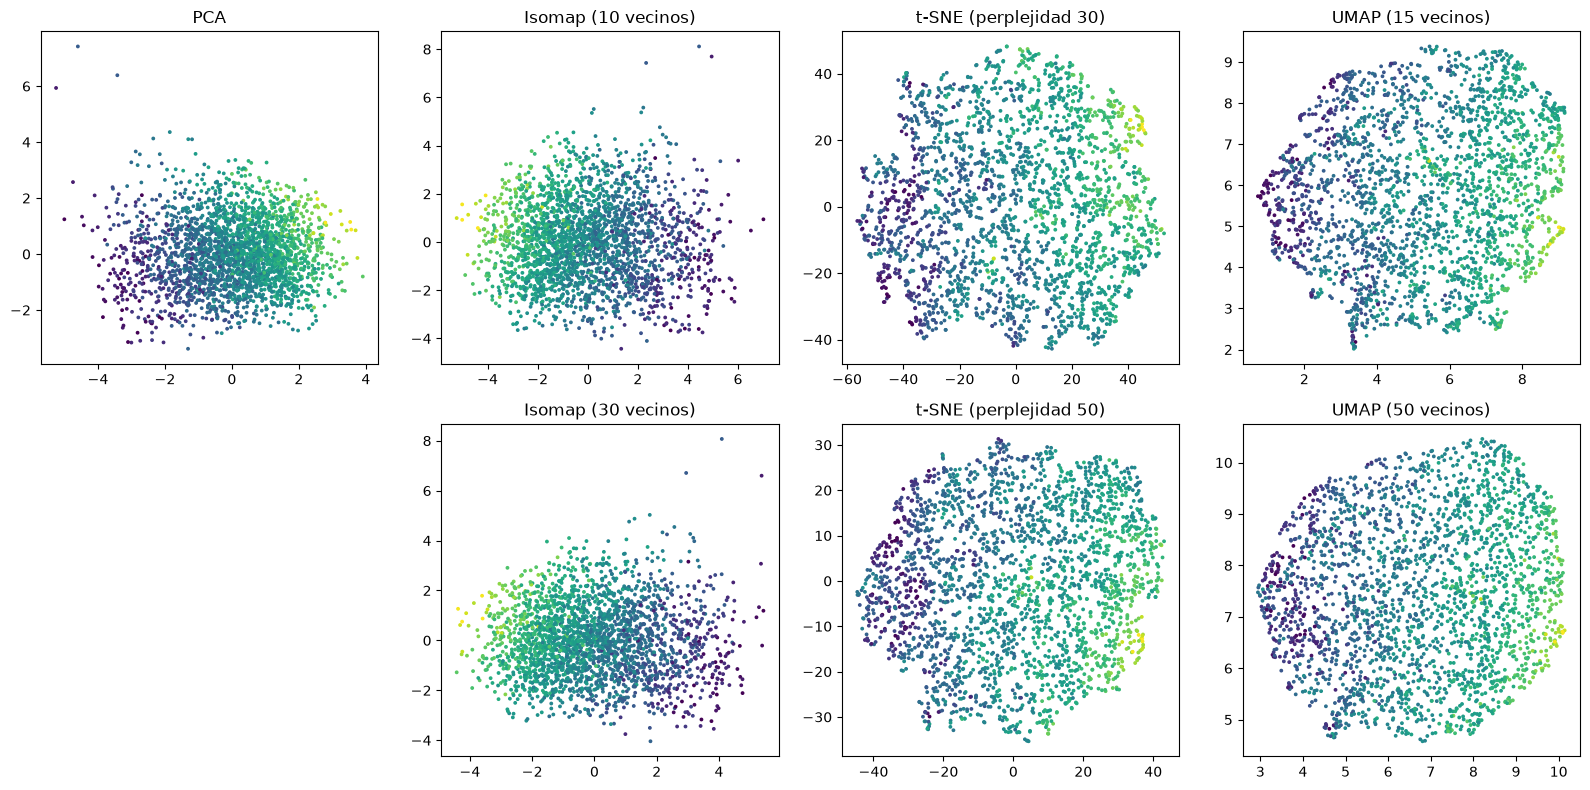

In [65]:
color = X_hog["n_visitas"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

axes[0, 0].scatter(Y_pca_h[:, 0], Y_pca_h[:, 1], c=color, cmap="viridis", s=3)
axes[0, 0].set_title("PCA")

axes[0, 1].scatter(Y_iso10[:, 0], Y_iso10[:, 1], c=color, cmap="viridis", s=3)
axes[0, 1].set_title("Isomap (10 vecinos)")

axes[0, 2].scatter(Y_tsne30[:, 0], Y_tsne30[:, 1], c=color, cmap="viridis", s=3)
axes[0, 2].set_title("t-SNE (perplejidad 30)")

axes[0, 3].scatter(Y_umap15[:, 0], Y_umap15[:, 1], c=color, cmap="viridis", s=3)
axes[0, 3].set_title("UMAP (15 vecinos)")

axes[1, 0].axis("off")

axes[1, 1].scatter(Y_iso30[:, 0], Y_iso30[:, 1], c=color, cmap="viridis", s=3)
axes[1, 1].set_title("Isomap (30 vecinos)")

axes[1, 2].scatter(Y_tsne50[:, 0], Y_tsne50[:, 1], c=color, cmap="viridis", s=3)
axes[1, 2].set_title("t-SNE (perplejidad 50)")

axes[1, 3].scatter(Y_umap50[:, 0], Y_umap50[:, 1], c=color, cmap="viridis", s=3)
axes[1, 3].set_title("UMAP (50 vecinos)")

plt.tight_layout()
plt.savefig("../salidas/figuras/02_mapas_hogares.png", dpi=150)
plt.show()

Los mapas se colorean con el número de visitas (morado: pocas; amarillo: muchas).
Arriba está cada método con su primer parámetro y abajo, con el segundo.
En todos se ve un **degradado ordenado** según las visitas, así que los mapas recogen bien este hábito.
No aparecen grupos separados como "islas": los hogares forman una **nube continua**.

## 6. Métricas y elección del mejor mapa
Medimos los 7 mapas con las mismas dos métricas que en el swiss roll. Ahora `X_hog` son los datos originales
de los hogares (7 variables) y cada `Y` es un mapa 2D. Guardamos la tabla en `salidas/metricas.csv`.

In [66]:
metricas = pd.DataFrame({
    "metodo": ["PCA", "Isomap", "Isomap", "t-SNE", "t-SNE", "UMAP", "UMAP"],
    "parametro": ["-", "10 vecinos", "30 vecinos", "perplejidad 30", "perplejidad 50", "15 vecinos", "50 vecinos"],
    "confianza": [trustworthiness(X_hog, Y_pca_h, n_neighbors=10),
                  trustworthiness(X_hog, Y_iso10, n_neighbors=10),
                  trustworthiness(X_hog, Y_iso30, n_neighbors=10),
                  trustworthiness(X_hog, Y_tsne30, n_neighbors=10),
                  trustworthiness(X_hog, Y_tsne50, n_neighbors=10),
                  trustworthiness(X_hog, Y_umap15, n_neighbors=10),
                  trustworthiness(X_hog, Y_umap50, n_neighbors=10)],
    "distancias": [correlacion_distancias(X_hog, Y_pca_h),
                   correlacion_distancias(X_hog, Y_iso10),
                   correlacion_distancias(X_hog, Y_iso30),
                   correlacion_distancias(X_hog, Y_tsne30),
                   correlacion_distancias(X_hog, Y_tsne50),
                   correlacion_distancias(X_hog, Y_umap15),
                   correlacion_distancias(X_hog, Y_umap50)],
}).round(3)

metricas.to_csv("../salidas/metricas.csv", index=False)
metricas

,metodo,parametro,confianza,distancias
0,PCA,-,0.816,0.781
1,Isomap,10 vecinos,0.815,0.763
2,Isomap,30 vecinos,0.819,0.771
3,t-SNE,perplejidad 30,0.979,0.629
4,t-SNE,perplejidad 50,0.978,0.615
5,UMAP,15 vecinos,0.924,0.649
6,UMAP,50 vecinos,0.884,0.646


**Elección:** t-SNE conserva mejor las vecindades (confianza 0,98), pero las distancias entre grupos de un mapa de t-SNE
no tienen significado, así que no es adecuado para agrupar. Elegimos **UMAP con 15 vecinos** (confianza 0,92), muy por
encima de PCA e Isomap (0,82). PCA gana en distancias porque conserva las distancias en línea recta, pero confunde más vecinos.
Isomap da resultados casi iguales a PCA: los datos de los hogares no forman una variedad tan curvada como el swiss roll.
Cambiar los parámetros apenas modifica las métricas, así que los resultados son estables.

## 7. Guardar mapas.csv para Segmentos
Guardamos las coordenadas 2D de cada hogar con la mejor configuración de cada método, junto a su `household_key`.
Segmentos usará `umap_1` y `umap_2`.

In [67]:
mapas = pd.DataFrame({
    "household_key": claves,
    "pca_1": Y_pca_h[:, 0], "pca_2": Y_pca_h[:, 1],
    "isomap_1": Y_iso30[:, 0], "isomap_2": Y_iso30[:, 1],
    "tsne_1": Y_tsne30[:, 0], "tsne_2": Y_tsne30[:, 1],
    "umap_1": Y_umap15[:, 0], "umap_2": Y_umap15[:, 1],
})

mapas.to_csv("../salidas/mapas.csv", index=False)
print(mapas.shape)
mapas.head()

(2475, 9)


,household_key,pca_1,pca_2,isomap_1,isomap_2,tsne_1,tsne_2,umap_1,umap_2
0,1,0.847354,-1.515522,-0.922791,-1.835636,23.777876,-30.785933,6.829750,8.841054
1,2,-0.180650,-1.269934,0.360344,-1.554253,4.823352,-30.791187,4.413118,8.593312
2,3,-0.115154,-0.782625,0.214526,-0.791392,-1.359145,-19.269722,4.998217,7.884427
3,4,-1.476592,-2.564391,1.910813,-2.928696,-34.232849,-29.308411,2.468768,8.047721
4,5,-0.920768,-0.531396,1.206138,-0.645414,-27.601433,-12.726082,3.247264,6.292050
